# manasight 07: palette or content?

**Hypothesis H2 (the main one):** a card's color is read from the *content* of its art (what is in the picture)
more than from its *palette* (which colors of paint are used).

So far the palette model reaches 34% and the CLIP probe 45%, but notebook 05 showed that CLIP's features contain the
palette too. To separate the two cues we change the pictures:

| Alteration | What it removes | What it keeps |
|---|---|---|
| **Grayscale** | the colors | the content (shapes, subjects, brightness) |
| **Shuffled tiles** | the content | the colors (every pixel is still there) |

If the model still works on grey pictures, it reads content. If it still works on shuffled pictures, it reads palette.

Two kinds of test:
- **Test A:** the probe from notebook 05, trained on normal pictures, is shown altered **test** pictures.
  This tells us what that model leans on.
- **Test B:** a new probe is trained **and** tested on grey pictures. It never sees a color, so whatever it scores is
  what content alone can do. This is the fair "content only" number, to set against the palette-only 34%.

CLIP has to look at every altered picture, so the first run takes about an hour on a CPU
(grey versions of all 43,573 pictures, shuffled versions of the 3,392 test pictures). It is saved and resumable.

Sections:
1. Load data, features and the two models
2. The alterations
3. CLIP features of the altered pictures
4. Test A: the trained probe on altered test pictures
5. Test B: trained and tested without color
6. Which colors need their color?
7. Type
8. Summary

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from manasight.data import COLOR_CLASSES, COLOR_NAMES, TYPE_CLASSES, load_cards
from manasight.clip import load_clip, image_features, load_image_features
from manasight.alter import to_square, to_grayscale, shuffle_tiles
from manasight.eda import load_thumbnails
from manasight.features import color_histogram
from manasight.evaluate import score

plt.rcParams["figure.dpi"] = 72
%config InlineBackend.figure_formats = ["jpeg"]   # paintings: jpeg keeps the notebook small

QUICK_TEST = False    # True: a few hundred pictures only, to check that everything runs

## 1. Load data, features and the two models

The two models from before, both logistic regression:
- **palette model** (notebook 03): 64 color-box shares per picture
- **CLIP probe** (notebook 05): 512 CLIP numbers per picture

In [2]:
all_cards = load_cards()
not_junk = ~all_cards.is_junk.to_numpy()
cards = all_cards[not_junk].reset_index(drop=True)
features = load_image_features(cards)
thumbs, sizes = load_thumbnails(all_cards)
thumbs = thumbs[not_junk]

in_main = cards.split.isin(["train", "val", "test"]).to_numpy()
if QUICK_TEST:
    keep = pd.concat([cards[cards.split == "train"].sample(300, random_state=0),
                      cards[cards.split == "val"].sample(60, random_state=0),
                      cards[cards.split == "test"].sample(60, random_state=0)]).index
    in_main = np.isin(np.arange(len(cards)), keep)

# from here on: only the pictures of the main split
main = cards[in_main].reset_index(drop=True)
main_features = features[in_main]
main_thumbs = thumbs[in_main]
is_train = (main.split == "train").to_numpy()
is_val = (main.split == "val").to_numpy()
is_test = (main.split == "test").to_numpy()
test_cards = main[is_test]
print(f"train {is_train.sum():,}   val {is_val.sum():,}   test {is_test.sum():,}")

clip_scaler = StandardScaler().fit(main_features[is_train])
clip_probe = LogisticRegression(C=0.001, max_iter=200).fit(clip_scaler.transform(main_features[is_train]), main.color[is_train])
type_probe = LogisticRegression(C=0.01, max_iter=200).fit(clip_scaler.transform(main_features[is_train]), main.type[is_train])

palette = color_histogram(main_thumbs, bins=4)
palette_scaler = StandardScaler().fit(palette[is_train])
palette_model = LogisticRegression(max_iter=200).fit(palette_scaler.transform(palette[is_train]), main.color[is_train])

def clip_score(model, test_features, labels):
    return score(labels, model.predict_proba(clip_scaler.transform(test_features)), model.classes_)

print("CLIP probe, normal test pictures:   ", {k: round(v, 3) for k, v in clip_score(clip_probe, main_features[is_test], test_cards.color).items()})
print("palette model, normal test pictures:", {k: round(v, 3) for k, v in
      score(test_cards.color, palette_model.predict_proba(palette_scaler.transform(palette[is_test])), palette_model.classes_).items()})

train 35,383   val 4,798   test 3,392
CLIP probe, normal test pictures:    {'accuracy': 0.446, 'macro-F1': 0.442, 'top-2': 0.675}
palette model, normal test pictures: {'accuracy': 0.34, 'macro-F1': 0.304, 'top-2': 0.542}


## 2. The alterations

All alterations work on the 224x224 square that CLIP actually sees.

**Shuffled tiles** come in five strengths. The picture is cut into a grid of tiles that are put back in random order:
2x2 leaves large pieces of the scene, 7x7 tiles are exactly the size of the patches CLIP reads a picture in,
and 224x224 moves every single pixel. In all of them the palette is exactly the same as in the original.

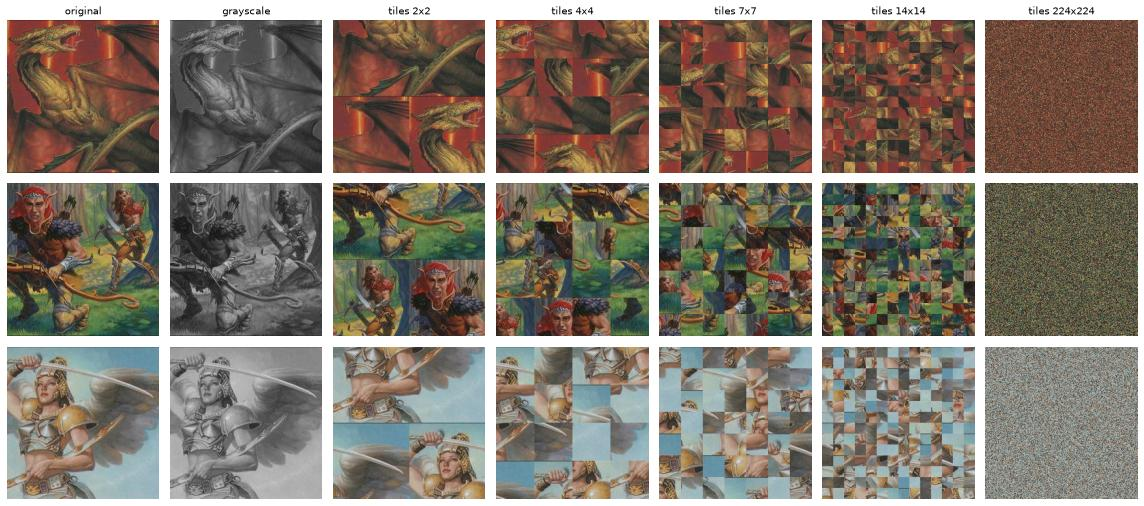

In [3]:
TILES = [2, 4, 7, 14, 224]

example_names = ["Shivan Dragon", "Serra Angel", "Llanowar Elves"]
examples = test_cards[test_cards.name.isin(example_names)].drop_duplicates("name")
if len(examples) == 0:
    examples = test_cards.head(3)

fig, axes = plt.subplots(len(examples), 7, figsize=(16, 2.4 * len(examples)), squeeze=False)
titles = ["original", "grayscale"] + [f"tiles {t}x{t}" for t in TILES]
for row, card in enumerate(examples.itertuples()):
    square = to_square(Image.open(card.path))
    versions = [square, to_grayscale(square)] + [shuffle_tiles(square, t, seed=0) for t in TILES]
    for ax, version, title in zip(axes[row], versions, titles):
        ax.imshow(version)
        ax.set_title(title if row == 0 else "", fontsize=10)
        ax.axis("off")
plt.tight_layout()
plt.show()

## 3. CLIP features of the altered pictures

- Grey versions of **all** pictures of the main split (train, val and test), for Test B.
- Shuffled versions of the **test** pictures only, for Test A.

About an hour on a CPU the first time. Everything is saved in chunks, so it is safe to stop and run again.

In [4]:
model, transform, tokenizer = load_clip()
suffix = "_quick" if QUICK_TEST else ""

def make_gray(image, number):
    return to_grayscale(to_square(image))

gray_features = image_features(main, model, transform, alter=make_gray, name="gray" + suffix)
print("grayscale:", gray_features.shape)

shuffled_features = {}
for tiles in TILES:
    def make_shuffled(image, number):
        return shuffle_tiles(to_square(image), tiles, seed=number)   # a different shuffle for every picture
    shuffled_features[tiles] = image_features(test_cards, model, transform, alter=make_shuffled,
                                              name=f"tiles{tiles}_test" + suffix)
    print(f"tiles {tiles}x{tiles}:", shuffled_features[tiles].shape)

  0%|          | 0/44 [00:00<?, ?it/s]

grayscale: (43573, 512)


  0%|          | 0/4 [00:00<?, ?it/s]

tiles 2x2: (3392, 512)


  0%|          | 0/4 [00:00<?, ?it/s]

tiles 4x4: (3392, 512)


... (2 outputs left out)

  0%|          | 0/4 [00:00<?, ?it/s]

tiles 14x14: (3392, 512)


  0%|          | 0/4 [00:00<?, ?it/s]

tiles 224x224: (3392, 512)


## 4. Test A: the trained probe on altered test pictures

The probe was trained on normal pictures. What happens to its test score when the color is removed, and when the
content is broken up more and more?

For the palette model the answers are known in advance for shuffling: its 64 color-box shares do not change when
pixels move, so it scores exactly the same. For grayscale it is computed.

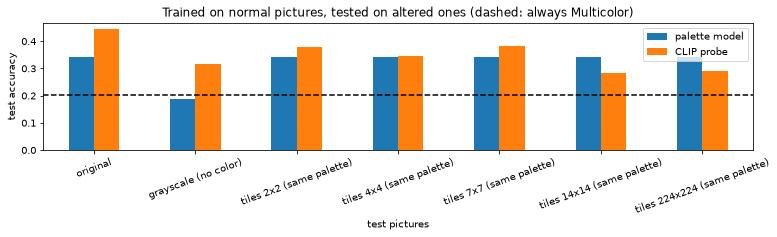

,palette model,CLIP probe
test pictures,,
original,0.340,0.446
grayscale (no color),0.189,0.317
tiles 2x2 (same palette),0.340,0.377
tiles 4x4 (same palette),0.340,0.347
tiles 7x7 (same palette),0.340,0.384
tiles 14x14 (same palette),0.340,0.285
tiles 224x224 (same palette),0.340,0.292


In [5]:
def gray_thumbs(pictures):
    # the same grey conversion as for the full pictures, on the tiny versions
    grey = pictures[..., 0] * 0.299 + pictures[..., 1] * 0.587 + pictures[..., 2] * 0.114
    grey = np.round(grey).astype(np.uint8)
    return np.stack([grey, grey, grey], axis=-1)

gray_palette = color_histogram(gray_thumbs(main_thumbs), bins=4)

palette_normal = score(test_cards.color, palette_model.predict_proba(palette_scaler.transform(palette[is_test])), palette_model.classes_)
palette_gray = score(test_cards.color, palette_model.predict_proba(palette_scaler.transform(gray_palette[is_test])), palette_model.classes_)

rows = [{"test pictures": "original", "palette model": palette_normal["accuracy"],
         "CLIP probe": clip_score(clip_probe, main_features[is_test], test_cards.color)["accuracy"]},
        {"test pictures": "grayscale (no color)", "palette model": palette_gray["accuracy"],
         "CLIP probe": clip_score(clip_probe, gray_features[is_test], test_cards.color)["accuracy"]}]
for tiles in TILES:
    rows.append({"test pictures": f"tiles {tiles}x{tiles} (same palette)", "palette model": palette_normal["accuracy"],
                 "CLIP probe": clip_score(clip_probe, shuffled_features[tiles], test_cards.color)["accuracy"]})
test_a = pd.DataFrame(rows).set_index("test pictures")

ax = test_a.plot.bar(figsize=(11, 3.4), rot=20)
ax.axhline(0.202, color="black", linestyle="--")
ax.set_ylabel("test accuracy")
ax.set_title("Trained on normal pictures, tested on altered ones (dashed: always Multicolor)")
plt.tight_layout()
plt.show()
test_a.round(3)

**Finding:** the probe leans on both cues, about equally.
- **Without color** it drops from 44.6% to 31.7% (13 points).
- **With the content broken up** it drops to 38% (2x2 tiles) and to 29% when every pixel is moved (15 points).
- The palette model is untouched by shuffling, as it must be, and without color it falls to 18.9%, below the
  majority guess.

Two details:
- With every pixel moved, the CLIP probe (29.2%) is *below* the palette model (34.0%), although both now have only
  the palette. A picture of pure colored noise is unlike anything CLIP has seen, so this is not a clean
  "palette only" number for CLIP. The palette model is the fair one for that, and Test B handles the other side.
- 7x7 tiles hurt less than 4x4 tiles (38.4% against 34.7%). 7x7 tiles are exactly the patches CLIP reads a picture
  in, so each patch stays whole and only their order changes; 4x4 tiles cut through the patches.

## 5. Test B: trained and tested without color

Test A has a weakness: the probe never saw a grey picture during training, so part of its drop may be surprise,
not missing information. Here a probe is trained on grey pictures and tested on grey pictures.
It cannot use hue at all. (Brightness is still there: a dark picture stays dark.)

The palette model gets the same treatment: trained and tested on grey thumbnails, where all it has left is how
bright the picture is.

In [6]:
gray_scaler = StandardScaler().fit(gray_features[is_train])
gray_probe = LogisticRegression(C=0.001, max_iter=200).fit(gray_scaler.transform(gray_features[is_train]), main.color[is_train])
gray_probabilities = gray_probe.predict_proba(gray_scaler.transform(gray_features[is_test]))
gray_result = score(test_cards.color, gray_probabilities, gray_probe.classes_)

gray_palette_scaler = StandardScaler().fit(gray_palette[is_train])
gray_palette_model = LogisticRegression(max_iter=200).fit(gray_palette_scaler.transform(gray_palette[is_train]), main.color[is_train])
gray_palette_result = score(test_cards.color, gray_palette_model.predict_proba(gray_palette_scaler.transform(gray_palette[is_test])),
                            gray_palette_model.classes_)

normal_probabilities = clip_probe.predict_proba(clip_scaler.transform(main_features[is_test]))
test_b = pd.DataFrame([
    {"model": "always Multicolor", "what it can use": "nothing", "accuracy": 0.202, "macro-F1": 0.048},
    {"model": "palette model on grey pictures", "what it can use": "brightness only", **gray_palette_result},
    {"model": "palette model", "what it can use": "palette only", **palette_normal},
    {"model": "CLIP probe on grey pictures", "what it can use": "content and brightness, no hue", **gray_result},
    {"model": "CLIP probe", "what it can use": "content and palette", **score(test_cards.color, normal_probabilities, clip_probe.classes_)},
]).set_index("model")
test_b.round(3)

,what it can use,accuracy,macro-F1,top-2
model,,,,
always Multicolor,nothing,0.202,0.048,NaN
palette model on grey pictures,brightness only,0.218,0.126,0.402
palette model,palette only,0.340,0.304,0.542
CLIP probe on grey pictures,"content and brightness, no hue",0.348,0.352,0.555
CLIP probe,content and palette,0.446,0.442,0.675


**Finding:** content alone and palette alone are worth the same.

| What the model can use | Accuracy | Above the majority guess |
|---|---|---|
| nothing (always Multicolor) | 20.2% | |
| brightness only | 21.8% | +1.6 |
| palette only | 34.0% | +13.8 |
| content and brightness, no hue | 34.8% | +14.6 |
| content and palette | 44.6% | +24.4 |

- **A model that never sees a color (34.8%) does as well as a model that sees nothing but colors (34.0%).**
- **Together they reach 44.6%.** The gain of both (+24.4) is close to the sum of the two single gains (+28.4), so the
  two cues mostly help on *different* cards. They are two largely separate sources of information.
- Brightness by itself is worth almost nothing.

**H2, as it was stated, is not supported:** content does not carry more than palette. It carries the same amount.
What is also refuted is the opposite idea, that color in art is "just the palette": half of what the model knows
survives when all color is removed.

## 6. Which colors need their color?

Share of each class found, with and without color (both CLIP probes from Test B).

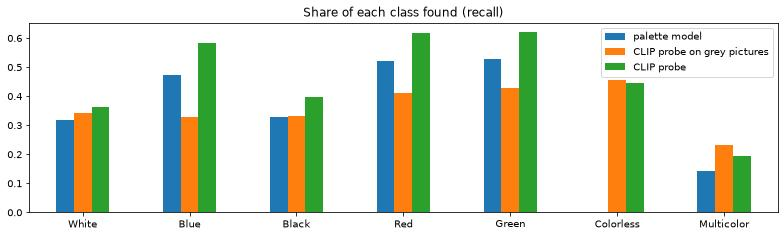

,palette model,CLIP probe on grey pictures,CLIP probe,lost without color
White,0.32,0.34,0.36,0.02
Blue,0.47,0.33,0.58,0.26
Black,0.33,0.33,0.40,0.07
Red,0.52,0.41,0.62,0.21
Green,0.53,0.43,0.62,0.20
Colorless,0.00,0.46,0.45,-0.01
Multicolor,0.14,0.23,0.19,-0.04


In [7]:
names = [COLOR_NAMES[c] for c in COLOR_CLASSES]
predicted_normal = clip_probe.classes_[normal_probabilities.argmax(axis=1)]
predicted_gray = gray_probe.classes_[gray_probabilities.argmax(axis=1)]
palette_predicted = palette_model.classes_[palette_model.predict_proba(palette_scaler.transform(palette[is_test])).argmax(axis=1)]

recall = pd.DataFrame({
    "palette model": confusion_matrix(test_cards.color, palette_predicted, labels=COLOR_CLASSES, normalize="true").diagonal(),
    "CLIP probe on grey pictures": confusion_matrix(test_cards.color, predicted_gray, labels=COLOR_CLASSES, normalize="true").diagonal(),
    "CLIP probe": confusion_matrix(test_cards.color, predicted_normal, labels=COLOR_CLASSES, normalize="true").diagonal(),
}, index=names)
recall["lost without color"] = recall["CLIP probe"] - recall["CLIP probe on grey pictures"]

recall[["palette model", "CLIP probe on grey pictures", "CLIP probe"]].plot.bar(figsize=(11, 3.4), rot=0,
                                                                              title="Share of each class found (recall)")
plt.tight_layout()
plt.show()
recall.round(2)

**Finding:** which cue matters depends on the color, and the split is clean.
- **Colorless is content only:** 46% found without any color in the picture, the same as with color, and 0% by the
  palette model. An artifact is recognized as an object.
- **White and Black hardly need their color** (they lose 2 and 7 points in grey). They are found through content
  and brightness.
- **Blue, Red and Green depend on hue:** they lose 26, 21 and 20 points in grey. For these three, the palette alone
  (47%, 52%, 53%) even beats content alone (33%, 41%, 43%).
- Multicolor does not get worse without color (23% against 19%).

This matches what the probe's weights said in notebook 05, read back as words: color words for Blue, object words
for Colorless. Here it is measured instead of read.

## 7. Type

Notebook 03 found that the palette says nothing about type. If that is right, removing the color should cost the type
probe almost nothing, and shuffling should destroy it.

In [8]:
gray_type_probe = LogisticRegression(C=0.01, max_iter=200).fit(gray_scaler.transform(gray_features[is_train]), main.type[is_train])

rows = [{"test pictures": "original", **clip_score(type_probe, main_features[is_test], test_cards.type)},
        {"test pictures": "grayscale, probe trained on normal pictures", **clip_score(type_probe, gray_features[is_test], test_cards.type)},
        {"test pictures": "grayscale, probe trained on grey pictures",
         **score(test_cards.type, gray_type_probe.predict_proba(gray_scaler.transform(gray_features[is_test])), gray_type_probe.classes_)}]
for tiles in TILES:
    rows.append({"test pictures": f"tiles {tiles}x{tiles}", **clip_score(type_probe, shuffled_features[tiles], test_cards.type)})
print("always Creature: accuracy 0.499, macro-F1 0.095")
pd.DataFrame(rows).set_index("test pictures").round(3)

always Creature: accuracy 0.499, macro-F1 0.095


,accuracy,macro-F1,top-2
test pictures,,,
original,0.578,0.396,0.742
"grayscale, probe trained on normal pictures",0.565,0.336,0.717
"grayscale, probe trained on grey pictures",0.575,0.373,0.728
tiles 2x2,0.370,0.302,0.547
tiles 4x4,0.188,0.178,0.372
tiles 7x7,0.330,0.233,0.527
tiles 14x14,0.157,0.103,0.342
tiles 224x224,0.128,0.046,0.292


**Finding:** type is content, as predicted.
- **Removing the color costs almost nothing:** 57.5% against 57.8% accuracy for a probe trained on grey pictures
  (macro-F1 0.373 against 0.396).
- **Breaking up the content destroys it:** 37% with 2x2 tiles, 13% with every pixel moved, far below the majority
  guess. (The same 7x7 oddity as in Test A shows here: whole patches in a new order keep more than cut patches.)

Type and color behave differently under the same two alterations, which is the clearest sign that the alterations
do what they are meant to do.

## 8. Summary

**Palette or content? Both, in equal parts, and they add up.**

| Test set, color (7 classes) | Accuracy | Macro-F1 |
|---|---|---|
| Always Multicolor | 20.2% | 0.048 |
| Brightness only (palette model on grey pictures) | 21.8% | 0.126 |
| Palette only (color histogram) | 34.0% | 0.304 |
| Content only (CLIP probe trained and tested on grey pictures) | 34.8% | 0.352 |
| Content and palette (CLIP probe) | 44.6% | 0.442 |

- Content alone and palette alone each lift the score about 14 points above the majority guess. Together: 24 points.
  They are mostly separate sources of information.
- **By color:** Colorless is read from content only. White and Black barely need their color. Blue, Red and Green
  lose 20 to 26 points without it; for those three the palette is the stronger cue.
- **Type is content:** no loss without color, destroyed by shuffling.

**H2 ("content carries more than palette") is not supported in that form.** The art carries a card's color in two
ways of about equal weight. Which one matters depends on the color: content for Colorless, White and Black,
palette for Blue, Red and Green. A model needs both to do well, which is why a pretrained model that sees both
(44.6%) clears a palette model (34.0%) and a network trained from scratch (the reference project's 36.8%).

**Next:** artist and era: does the model partly recognize artists, and how much did the look of the colors change
over thirty years?
